In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
import joblib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score



In [2]:
train = pd.read_csv('train_u6lujuX_CVtuZ9i.csv')
test = pd.read_csv('test_Y3wMUE5_7gLdaTN.csv')

print(train.shape)
print(test.shape)
train.head()

(614, 13)
(367, 12)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


Missing Values

In [3]:
print(train.isnull().sum())
# it is expected to have null values but small percent
# most of them for credit history

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [5]:
# remove loan lable so the model can predict and learn
#removing load id as it is not important info
X = train.drop(columns=['Loan_ID', 'Loan_Status'])
y = train['Loan_Status'].map({'Y': 1, 'N': 0})
test_X = test.drop(columns=['Loan_ID'])

# 80% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# handling missing values ( X_train only)
median_loan = X_train['LoanAmount'].median()
for data in [X_train, X_val, test_X]:
    data['LoanAmount'] = data['LoanAmount'].fillna(median_loan)

mode_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed',
             'Credit_History', 'Loan_Amount_Term']
for col in mode_cols:
    most_common = X_train[col].mode()[0]
    for data in [X_train, X_val, test_X]:
        data[col] = data[col].fillna(most_common)


In [6]:
print(X_train.isnull().sum().sum(), X_val.isnull().sum().sum(), test_X.isnull().sum().sum())

0 0 0


In [7]:
# convert words into 0/1 columns
X_train = pd.get_dummies(X_train)
X_val = pd.get_dummies(X_val)
test_X = pd.get_dummies(test_X)

# ensure validation and test have the same columns as training
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
test_X = test_X.reindex(columns=X_train.columns, fill_value=0)

print(X_train.shape, X_val.shape, test_X.shape)

(491, 20) (123, 20) (367, 20)


Models Traning and Accuracy

In [9]:
#i wanted to compare two models as i spent time yesterday
#duiring session reading about them

# Model # 1 is Logistic Regression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

# Model # 2 is Random Forest
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Accuracy applied on the validation set
print("Logistic Regression:", log_model.score(X_val, y_val))
print("Random Forest:", rf_model.score(X_val, y_val))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression: 0.8617886178861789
Random Forest: 0.8211382113821138


In [11]:
log_pred = log_model.predict(X_val)
rf_pred = rf_model.predict(X_val)

for name, pred in [("Logistic Regression", log_pred), ("Random Forest", rf_pred)]:
    print(name)
    print(confusion_matrix(y_val, pred))
    print("Accuracy :", accuracy_score(y_val, pred))
    print("Precision:", precision_score(y_val, pred))
    print("Recall   :", recall_score(y_val, pred))
    print()

Logistic Regression
[[22 16]
 [ 1 84]]
Accuracy : 0.8617886178861789
Precision: 0.84
Recall   : 0.9882352941176471

Random Forest
[[24 14]
 [ 8 77]]
Accuracy : 0.8211382113821138
Precision: 0.8461538461538461
Recall   : 0.9058823529411765



In [13]:

#save the model
joblib.dump(log_model, 'loan_model.joblib')
loaded_model = joblib.load('loan_model.joblib')

# predecting on the test data
test_pred = loaded_model.predict(test_X)
test_conf = loaded_model.predict_proba(test_X)[:, 1]

# the results
results = pd.DataFrame({
    'Loan_ID': test['Loan_ID'],
    'Loan_Status': pd.Series(test_pred).map({1: 'Y', 0: 'N'}),
    'Approval_Confidence': test_conf.round(2)
})
results.to_csv('predictions.csv', index=False)
results.head(10)

,Loan_ID,Loan_Status,Approval_Confidence
0,LP001015,Y,0.81
1,LP001022,Y,0.74
2,LP001031,Y,0.85
3,LP001035,Y,0.85
4,LP001051,Y,0.62
5,LP001054,Y,0.66
6,LP001055,Y,0.74
7,LP001056,N,0.13
8,LP001059,Y,0.87
9,LP001067,Y,0.72


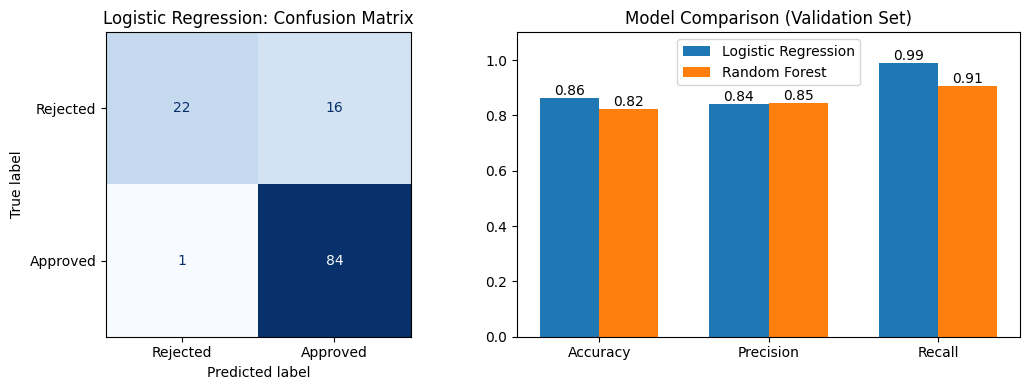

In [15]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Chart 1, confusion matrix for Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_val, log_pred,
    display_labels=['Rejected', 'Approved'],
    cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Logistic Regression: Confusion Matrix')

# Chart 2, compare the two models
metrics = ['Accuracy', 'Precision', 'Recall']
log_scores = [accuracy_score(y_val, log_pred),
              precision_score(y_val, log_pred),
              recall_score(y_val, log_pred)]
rf_scores = [accuracy_score(y_val, rf_pred),
             precision_score(y_val, rf_pred),
             recall_score(y_val, rf_pred)]

x = np.arange(len(metrics))
width = 0.35
bars1 = axes[1].bar(x - width/2, log_scores, width, label='Logistic Regression')
bars2 = axes[1].bar(x + width/2, rf_scores, width, label='Random Forest')
axes[1].bar_label(bars1, fmt='%.2f')
axes[1].bar_label(bars2, fmt='%.2f')
axes[1].set_xticks(x)
axes[1].set_xticklabels(metrics)
axes[1].set_ylim(0, 1.1)
axes[1].set_title('Model Comparison (Validation Set)')
axes[1].legend()

plt.tight_layout()
plt.savefig('evaluation.png', dpi=150)
plt.show()

In [16]:
print(results['Loan_Status'].value_counts())
print("Uncertain (0.4 to 0.6):", results['Approval_Confidence'].between(0.4, 0.6).sum())
print("Random Forest train:", rf_model.score(X_train, y_train))
print("Random Forest validation:", rf_model.score(X_val, y_val))

Loan_Status
Y    306
N     61
Name: count, dtype: int64
Uncertain (0.4 to 0.6): 10
Random Forest train: 1.0
Random Forest validation: 0.8211382113821138


In [17]:
pip install gradio

In [18]:
!pip install -q gradio


The Interface

In [19]:

import gradio as gr

def predict_loan(gender, married, dependents, education, self_employed,
                 applicant_income, coapplicant_income, loan_amount,
                 loan_term, credit_history, property_area):
    row = pd.DataFrame([{
        'Gender': gender, 'Married': married, 'Dependents': dependents,
        'Education': education, 'Self_Employed': self_employed,
        'ApplicantIncome': applicant_income,
        'CoapplicantIncome': coapplicant_income,
        'LoanAmount': loan_amount, 'Loan_Amount_Term': loan_term,
        'Credit_History': float(credit_history),
        'Property_Area': property_area}])

    row = pd.get_dummies(row)
    row = row.reindex(columns=X_train.columns, fill_value=0)

    prob = loaded_model.predict_proba(row)[0, 1]
    decision = 'Approved' if prob >= 0.5 else 'Rejected'
    return f"{decision} (approval confidence: {prob:.2f})"

demo = gr.Interface(
    fn=predict_loan,
    inputs=[
        gr.Dropdown(['Male', 'Female'], value='Male', label='Gender'),
        gr.Dropdown(['Yes', 'No'], value='Yes', label='Married'),
        gr.Dropdown(['0', '1', '2', '3+'], value='0', label='Dependents'),
        gr.Dropdown(['Graduate', 'Not Graduate'], value='Graduate', label='Education'),
        gr.Dropdown(['No', 'Yes'], value='No', label='Self Employed'),
        gr.Number(value=5000, label='Applicant Income'),
        gr.Number(value=0, label='Coapplicant Income'),
        gr.Number(value=128, label='Loan Amount (in thousands)'),
        gr.Number(value=360, label='Loan Term (months)'),
        gr.Dropdown([1, 0], value=1, label='Credit History (1 = good, 0 = bad)'),
        gr.Dropdown(['Urban', 'Semiurban', 'Rural'], value='Urban', label='Property Area'),
    ],
    outputs=gr.Textbox(label='Prediction'),
    title='Loan Approval Predictor')

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2a397398e1a3aaca89.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
